# Boréal Marché — Association-rule mining (Apriori)
Offline part of the system: loads 1,000,000 baskets, mines rules with `mlxtend.apriori`, evaluates them, and saves `models/rules.json` + `models/metadata.json` for the Streamlit app.

**Run with Kernel → Restart & Run All.** Total run time is about 5 minutes. The slow default-settings test (Phase 2.1) is switched off by default — see `RUN_DEFAULT_APRIORI`.

In [ ]:
# ── Setup: every import and setting used in this notebook ──
# Environment: conda env "boreal" (Python 3.12) — packages in ../requirements.txt
import os, json, time, datetime, platform, tracemalloc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display

import mlxtend
from mlxtend.frequent_patterns import apriori, association_rules

# Paths (the notebook lives in notebooks/, so everything is one level up)
DATA_DIR    = '../data'
MODELS_DIR  = '../models'
REPORTS_DIR = '../reports'
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)

# Thresholds chosen for the final rule set (justified in Phases 2 and 3)
MIN_SUPPORT    = 0.01
MIN_CONFIDENCE = 0.1
MIN_LIFT       = 1.2

# Phase 2.1 runs Apriori with its DEFAULT settings, which needs 8-70 GB of RAM and can freeze the PC.
# Leave False to show the results already recorded; set True only to re-measure them.
RUN_DEFAULT_APRIORI = False

pd.set_option('display.max_colwidth', 80)
pd.set_option('display.width', 200)

print('Working directory:', os.getcwd())
print('Data files:', os.listdir(DATA_DIR))
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | mlxtend {mlxtend.__version__}')

['products.csv', 'transactionsdata.zip']


## Phase 1 - Load and prepare

### 1.1 Load and verify the data

In [ ]:
tx = pd.read_csv(f'{DATA_DIR}/transactionsdata.zip', parse_dates=['Date'])
products = pd.read_csv(f'{DATA_DIR}/products.csv')

print(tx['TransactionID'].nunique(), 'baskets')     # expect 1,000,000
print(tx['Item'].nunique(), 'products')              # expect 98
print(len(tx) / tx['TransactionID'].nunique())       # expect 8.38 items per basket
print(tx.duplicated(['TransactionID','Item']).sum()) # expect 0 (no item twice in a basket)
print('Items missing from products.csv:', set(tx['Item']) - set(products['Item']))

1000000 baskets
98 products
8.379837
0


### 1.2 Build the boolean baskets × products table
Fast method: integer-code baskets and items with `pd.factorize`, then write `True` into a NumPy bool array.

In [ ]:
t = time.perf_counter()
row, basket_ids = pd.factorize(tx['TransactionID'])
col, items      = pd.factorize(tx['Item'])
B = np.zeros((len(basket_ids), len(items)), dtype=bool)
B[row, col] = True
basket = pd.DataFrame(B, index=basket_ids, columns=items)
fast_seconds = time.perf_counter() - t
print(f'factorize + NumPy: {fast_seconds:.2f}s, {basket.memory_usage().sum()/1e6:.0f} MB '
      f'(98 MB of bool data + 8 MB int64 TransactionID index)')
print(basket.shape)

1.18s, 106 MB


Naive method for comparison (`crosstab` builds an int64 count table first, then converts):

In [ ]:
t = time.perf_counter()
naive = pd.crosstab(tx['TransactionID'], tx['Item']).astype(bool)
naive_seconds = time.perf_counter() - t
print(f'crosstab: {naive_seconds:.1f}s  vs  factorize: {fast_seconds:.2f}s')
del naive   # free the memory, we keep the fast version

64.49646489997394


### 1.3 Product frequencies

In [ ]:
freq = basket.mean().sort_values(ascending=False)   # share of baskets containing each item
display(freq.head(10))
display(freq.tail(5))

Sac réutilisable     0.900026
Biscuits             0.161439
Noix mélangées       0.155189
Beurre d'arachide    0.153726
Bière                0.150468
Savon à vaisselle    0.149820
Fromage cheddar      0.143457
Charbon de bois      0.140561
Papier hygiénique    0.139758
Céréales             0.139198
dtype: float64

Safran                         0.000818
Huile de truffe                0.000817
Caviar                         0.000810
Vinaigre balsamique vieilli    0.000779
Foie gras                      0.000756
dtype: float64

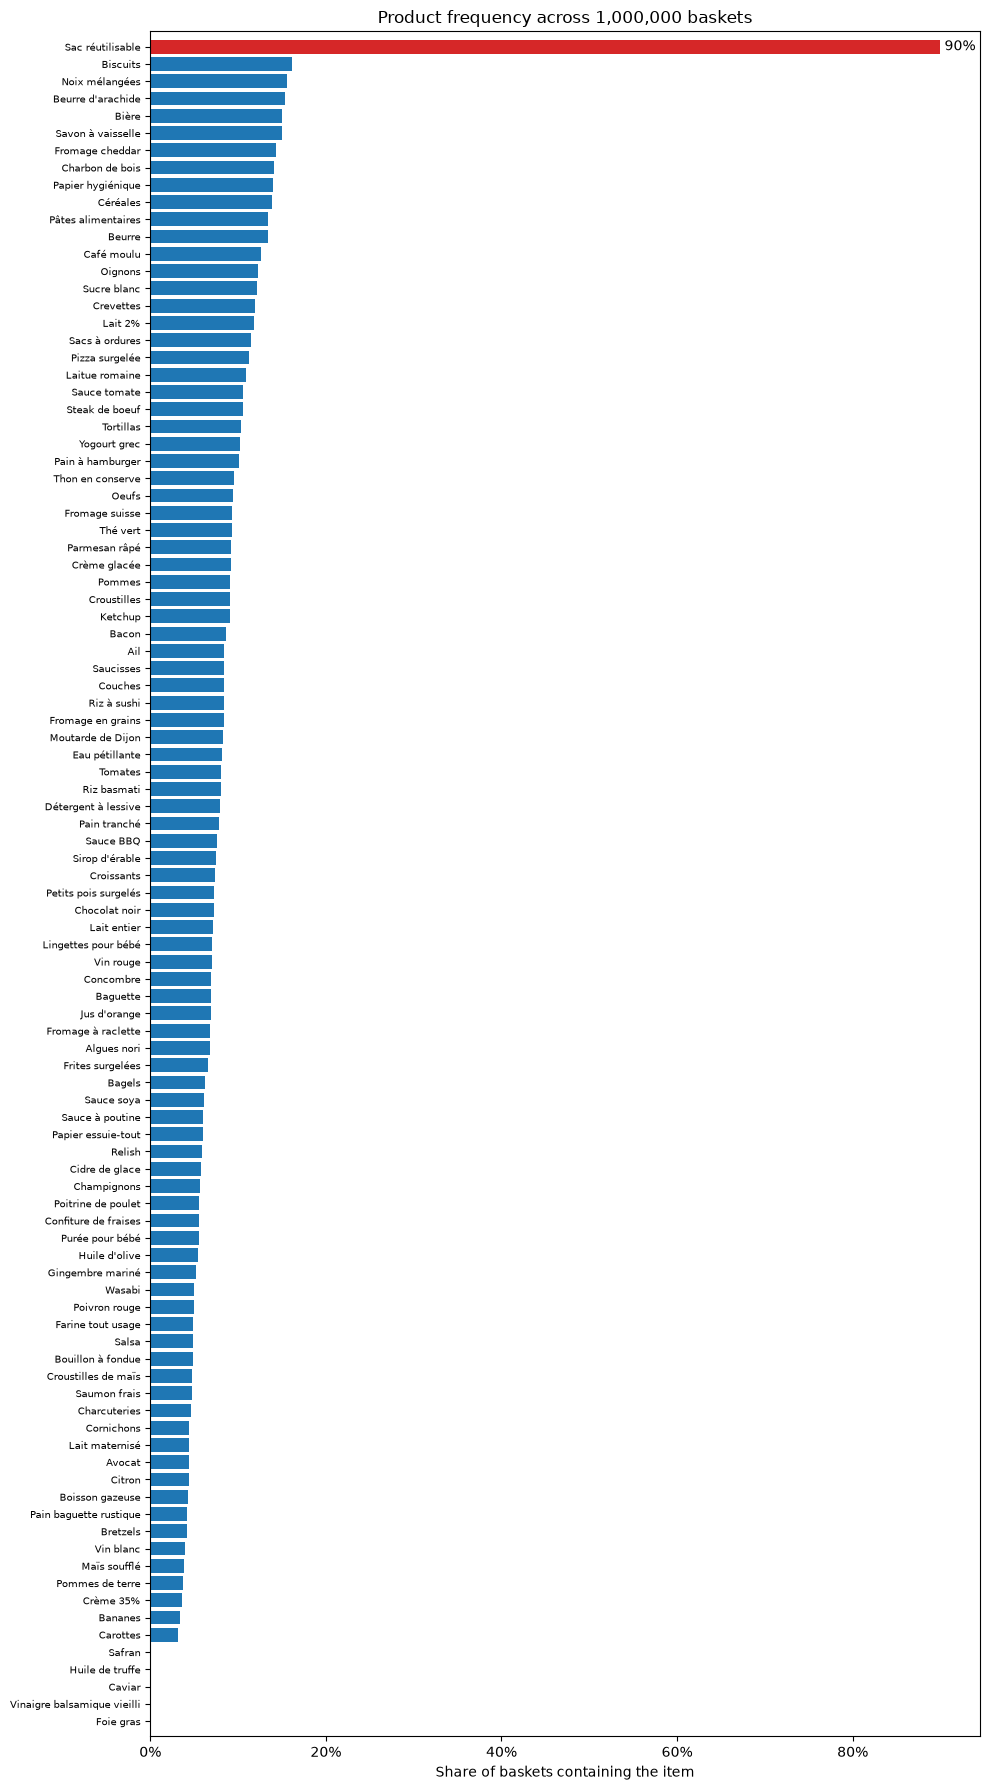

In [ ]:
# The 5 specialty items at the bottom are only ~0.08%, so their bars are too small to see:
# evidence that the app will not be able to recommend them.
freq_plot = freq.sort_values()                      # smallest at the bottom of a barh
colors = ['tab:red' if i == 'Sac réutilisable' else 'tab:blue' for i in freq_plot.index]

fig, ax = plt.subplots(figsize=(10, 18))            # tall, so all 98 names are readable
ax.barh(freq_plot.index, freq_plot.values, color=colors)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlabel('Share of baskets containing the item')
ax.set_title('Product frequency across 1,000,000 baskets')
ax.tick_params(axis='y', labelsize=7)
ax.margins(y=0.005)
ax.text(freq.iloc[0], len(freq) - 1, f' {freq.iloc[0]:.0%}', va='center')
plt.tight_layout()
plt.show()

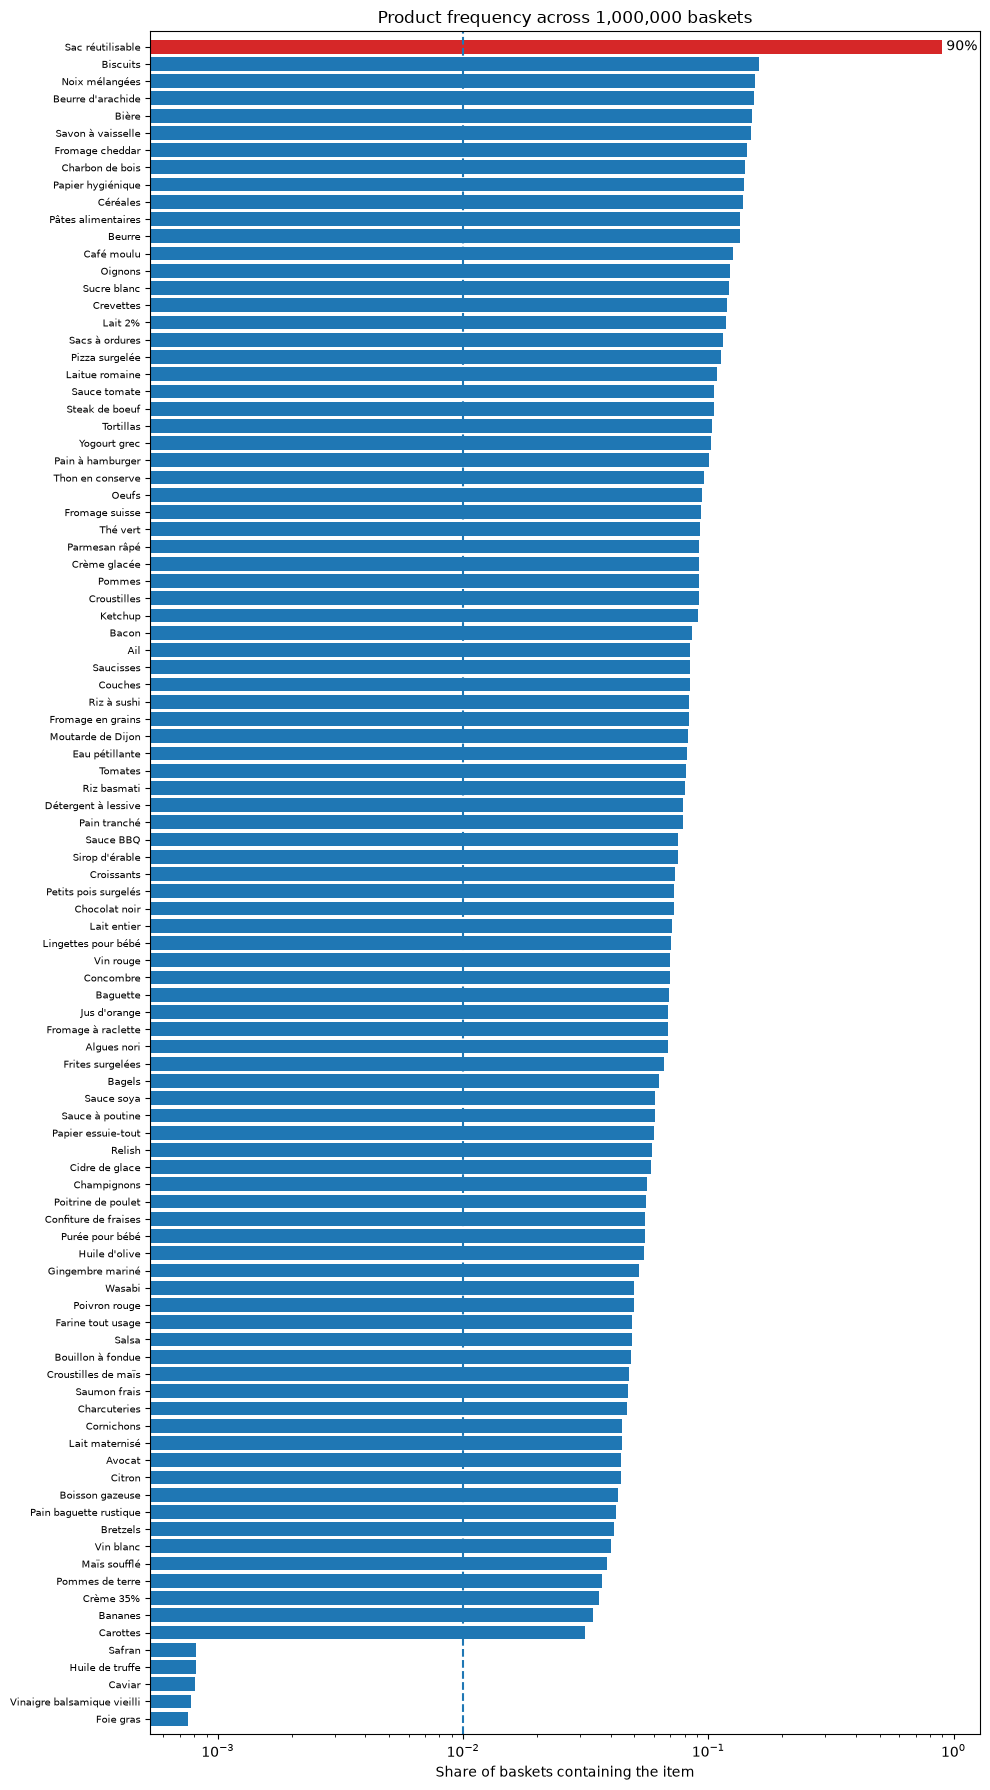

In [ ]:
# Same chart on a log scale: the specialty items become visible, and the dashed line is MIN_SUPPORT
fig, ax = plt.subplots(figsize=(10, 18))
ax.barh(freq_plot.index, freq_plot.values, color=colors)
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xscale('log')
ax.axvline(MIN_SUPPORT, ls='--', color='black', label=f'min_support = {MIN_SUPPORT:.0%}')
ax.set_xlabel('Share of baskets containing the item (log scale)')
ax.set_title('Product frequency vs the mining threshold')
ax.tick_params(axis='y', labelsize=7)
ax.margins(y=0.005)
ax.legend()
plt.tight_layout()
plt.show()

### 1.4 
Troublemaking product = Sac reutilisable
- When a product appears in 90% of all shopping carts, it naturally triggers a massive amount of high-confidence rules (like 'X → reusable bag'). 
- However, these rules are functionally useless because customers are buying the bag regardless of what else is in their cart.
- Also the 5 specialty products will not be recommended since they will not reach the min_support cutoff.

### 1.5 Duplicate product: Baguette vs Pain baguette rustique

lift(Baguette, Pain baguette rustique) = 1.027


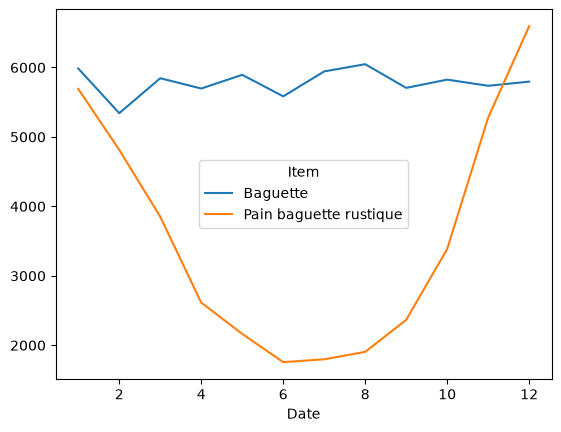

In [ ]:
monthly = tx.groupby([tx.Date.dt.month, 'Item']).size().unstack()
monthly[['Baguette', 'Pain baguette rustique']].plot(title='Baskets per month')
plt.show()

a, b = basket['Baguette'], basket['Pain baguette rustique']
lift_ab = (a & b).mean() / (a.mean() * b.mean())
print(f'lift(Baguette, Pain baguette rustique) = {lift_ab:.3f}')   # expected ~1.03

# What is each one bought with? (top 5 partners by lift)
co = basket.astype(np.float32).T @ basket.astype(np.float32) / len(basket)
lift_matrix = co / np.outer(freq.reindex(co.index), freq.reindex(co.index))
for item in ['Baguette', 'Pain baguette rustique']:
    print(item, '->', lift_matrix[item].drop(item).sort_values(ascending=False).head(5).round(2).to_dict())

**Decision — merge or keep separate?**


## Phase 2

In [34]:
from mlxtend.frequent_patterns import apriori
import time

default_runs = []
for ms in [0.05, 0.02, 0.01, 0.005]:
    t = time.perf_counter()
    try:
        it = apriori(basket, min_support=ms, use_colnames=True)   # low_memory=False (default)
        outcome = f'OK: {len(it)} itemsets'
    except MemoryError as e:
        outcome = f'MemoryError: {e}'
    secs = time.perf_counter() - t
    print(f'min_support={ms}: {outcome} ({secs:.1f}s)')
    default_runs.append(dict(min_support=ms, outcome=outcome, seconds=round(secs, 1)))

min_support=0.05: OK: 191 itemsets (64.4s)
min_support=0.02: OK: 658 itemsets (210.3s)
min_support=0.01: MemoryError: Unable to allocate 14.2 GiB for an array with shape (5099, 3, 1000000) and data type bool (132.7s)
min_support=0.005: MemoryError: Unable to allocate 72.6 GiB for an array with shape (25975, 3, 1000000) and data type bool (161.7s)


In [36]:
import time, tracemalloc
import association_rules
results = []
for ms in [0.05, 0.02, 0.01, 0.005]:
    tracemalloc.start(); t = time.perf_counter()
    itemsets = apriori(basket, min_support=ms, use_colnames=True, low_memory=True)
    rules = association_rules(itemsets, metric='confidence', min_threshold=0.1)
    elapsed = time.perf_counter() - t
    _, peak = tracemalloc.get_traced_memory(); tracemalloc.stop()
    results.append(dict(min_support=ms, itemsets=len(itemsets), rules=len(rules),
                        seconds=round(elapsed, 1), peak_GB=round(peak/1e9, 2),
                        longest=itemsets['itemsets'].map(len).max()))
pd.DataFrame(results)

ModuleNotFoundError: No module named 'association_rules'

## Phase 3

# 3.1
Definitions:
- Support: the share of all baskets that contain the whole set of items.
- Confidence: among baskets that contain the left-hand items, the share that also contain the right-hand item.
- Lift: how many times more often the right-hand item is bought with the left-hand items than it would be by chance alone.

In [37]:
# 3.2
simple = rules[(rules.antecedents.map(len) == 1) & (rules.consequents.map(len) == 1)].copy()
simple['if']   = simple.antecedents.map(lambda s: next(iter(s)))
simple['then'] = simple.consequents.map(lambda s: next(iter(s)))
cols = ['if', 'then', 'support', 'confidence', 'lift']
simple.sort_values('confidence', ascending=False)[cols].head(10)
simple.sort_values('lift', ascending=False)[cols].head(10)

,if,then,support,confidence,lift
1188,Bouillon à fondue,Fromage à raclette,0.033651,0.696780,10.170786
1187,Fromage à raclette,Bouillon à fondue,0.033651,0.491198,10.170786
1251,Fromage à raclette,Charcuteries,0.031932,0.466106,9.975519
1252,Charcuteries,Fromage à raclette,0.031932,0.683403,9.975519
1206,Fromage à raclette,Cornichons,0.029733,0.434008,9.772967
1207,Cornichons,Fromage à raclette,0.029733,0.669526,9.772967
1236,Pain baguette rustique,Fromage à raclette,0.027627,0.654374,9.551784
1235,Fromage à raclette,Pain baguette rustique,0.027627,0.403267,9.551784
1090,Algues nori,Riz à sushi,0.054431,0.795019,9.504685
1089,Riz à sushi,Algues nori,0.054431,0.650738,9.504685


In [ ]:
# 3.3 - Explinations

In [38]:
# 3.4
f = rules[rules.lift > 1]
(f.consequents.map(lambda s: 'Sac réutilisable' in s)).sum()

np.int64(12309)

## Phase 4

## Phase 5